# Phase 1 Task B — Efficiency Benchmark (5 Models)

**Metrics Evaluated:**
- FLOPs (G)
- Params (M)
- Inference (ms/img, batch=1, 100 runs, 10 warm-up)
- Size (MB)
- VRAM (GB, max allocated during inference)

Theo yêu cầu phần 4.4 trong WoodID_plan.md

In [1]:
from pathlib import Path
NOTEBOOK = Path("__file__").resolve()
ROOT = NOTEBOOK
for _ in range(10):
    ROOT = ROOT.parent
    if (ROOT / "pyproject.toml").exists() or (ROOT / ".git").exists(): break
import sys, os
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
print(f"[ROOT] {ROOT}")

[ROOT] /workspace/woodbench


In [2]:
from dotenv import load_dotenv
dotenv_path = ROOT / ".env"
load_dotenv(dotenv_path)
print(f"[.env] Loaded from {dotenv_path}")

import subprocess, sys, os
for pkg in ["timm", "ptflops", "pandas", "matplotlib", "seaborn", "wandb", "python-dotenv"]:
    try: __import__(pkg.replace("-", "_"))
    except: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

os.environ.setdefault("WANDB_API_KEY", os.getenv("WANDB_API_KEY", ""))

[.env] Loaded from /workspace/woodbench/.env


'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'

In [3]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wandb
import json
from ptflops import get_model_complexity_info
from src.models import create_model

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[Device] {DEVICE}")

[Device] cuda


In [4]:
def measure_efficiency(model_name: str, num_classes: int = 20) -> dict:
    import os
    print(f"\n{'='*50}\nEvaluating {model_name}\n{'='*50}")
    
    # 1. Create Model
    model = create_model(model_name, num_classes=num_classes, pretrained=False).to(DEVICE)
    model.eval()
    
    # 2. Params
    total_params = sum(p.numel() for p in model.parameters())
    params_m = total_params / 1e6
    
    # 3. Size (MB)
    tmp_path = "tmp_model.pth"
    torch.save(model.state_dict(), tmp_path)
    size_mb = os.path.getsize(tmp_path) / (1024 * 1024)
    os.remove(tmp_path)
    
    # 4. FLOPs (G)
    macs, params_fl = get_model_complexity_info(
        model, (3, 224, 224), as_strings=False, print_per_layer_stat=False, verbose=False
    )
    flops_g = (macs * 2) / 1e9  # 1 MAC = 2 FLOPs typically, ptflops returns MACs
    
    # 5. Inference Time & VRAM
    dummy_input = torch.randn(1, 3, 224, 224).to(DEVICE)
    
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.empty_cache()
        
        # Warm-up
        with torch.no_grad():
            for _ in range(10):
                _ = model(dummy_input)
        
        # Measure time
        starter, ender = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        timings = np.zeros((100, 1))
        
        with torch.no_grad():
            for rep in range(100):
                starter.record()
                _ = model(dummy_input)
                ender.record()
                torch.cuda.synchronize()
                timings[rep] = starter.elapsed_time(ender)
                
        inf_time_ms = np.mean(timings)
        vram_gb = torch.cuda.max_memory_allocated() / (1024**3)
    else:
        import time
        # Warm-up
        with torch.no_grad():
            for _ in range(10):
                _ = model(dummy_input)
        
        # Measure time
        timings = []
        with torch.no_grad():
            for _ in range(100):
                start_time = time.perf_counter()
                _ = model(dummy_input)
                timings.append((time.perf_counter() - start_time) * 1000)
                
        inf_time_ms = np.mean(timings)
        vram_gb = 0.0 # N/A on CPU

    result = {
        "Model": model_name,
        "Params (M)": round(params_m, 2),
        "Size (MB)": round(size_mb, 2),
        "FLOPs (G)": round(flops_g, 2),
        "Inference Time (ms)": round(float(inf_time_ms), 2),
        "VRAM (GB)": round(float(vram_gb), 3)
    }
    
    print(f"Params: {result['Params (M)']} M")
    print(f"Size: {result['Size (MB)']} MB")
    print(f"FLOPs: {result['FLOPs (G)']} G")
    print(f"Inference: {result['Inference Time (ms)']} ms")
    print(f"VRAM: {result['VRAM (GB)']} GB")
    
    return result

In [5]:
MODELS = [
    "resnet50",
    "efficientnet_b3",
    "mobilenetv3_large",
    "convnext_tiny",
    "swin_tiny"
]

results = []
for m in MODELS:
    res = measure_efficiency(m, num_classes=20)
    results.append(res)
    
df_results = pd.DataFrame(results)
display(df_results)


Evaluating resnet50
Params: 23.55 M
Size: 90.14 MB
FLOPs: 8.26 G
Inference: 5.09 ms
VRAM: 0.107 GB

Evaluating efficientnet_b3
Params: 10.73 M
Size: 41.45 MB
FLOPs: 1.9 G
Inference: 10.83 ms
VRAM: 0.158 GB

Evaluating mobilenetv3_large
Params: 4.23 M
Size: 16.32 MB
FLOPs: 0.44 G
Inference: 5.2 ms
VRAM: 0.032 GB

Evaluating convnext_tiny
Params: 27.84 M
Size: 106.25 MB
FLOPs: 8.96 G
Inference: 4.75 ms
VRAM: 0.143 GB

Evaluating swin_tiny
Params: 27.53 M
Size: 105.1 MB
FLOPs: 8.76 G
Inference: 8.7 ms
VRAM: 0.252 GB


,Model,Params (M),Size (MB),FLOPs (G),Inference Time (ms),VRAM (GB)
0,resnet50,23.55,90.14,8.26,5.09,0.107
1,efficientnet_b3,10.73,41.45,1.90,10.83,0.158
2,mobilenetv3_large,4.23,16.32,0.44,5.20,0.032
3,convnext_tiny,27.84,106.25,8.96,4.75,0.143
4,swin_tiny,27.53,105.10,8.76,8.70,0.252


In [6]:
# Save Results
out_dir = ROOT / "data" / "experiments" / "Task-B" / "main" / "efficiency"
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / "efficiency_results.json"

with open(out_path, "w") as f:
    json.dump(results, f, indent=4)
print(f"\n[Saved] Results to {out_path}")

# Export to CSV for easy inclusion in report
csv_path = out_dir / "efficiency_results.csv"
df_results.to_csv(csv_path, index=False)
print(f"[Saved] CSV to {csv_path}")


[Saved] Results to /workspace/woodbench/data/experiments/Task-B/main/efficiency/efficiency_results.json
[Saved] CSV to /workspace/woodbench/data/experiments/Task-B/main/efficiency/efficiency_results.csv


In [7]:
# Log to wandb
run = wandb.init(
    project="woodbench-taskB-clean",
    name="efficiency_benchmark",
    job_type="benchmark",
    dir=str(out_dir)
)

wandb_table = wandb.Table(dataframe=df_results)
run.log({"efficiency_table": wandb_table})
run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: ny0g507h3p (ny0g507h3p_) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


/tmp/ipykernel_238299/3133952774.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_results, x="Model", y=metric, ax=ax, palette=colors)
/tmp/ipykernel_238299/3133952774.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_238299/3133952774.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_results, x="Model", y=metric, ax=ax, palette=colors)
/tmp/ipykernel_238299/3133952774.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after s

[Saved] Plot to /workspace/woodbench/data/experiments/Task-B/main/efficiency/efficiency_comparison.png


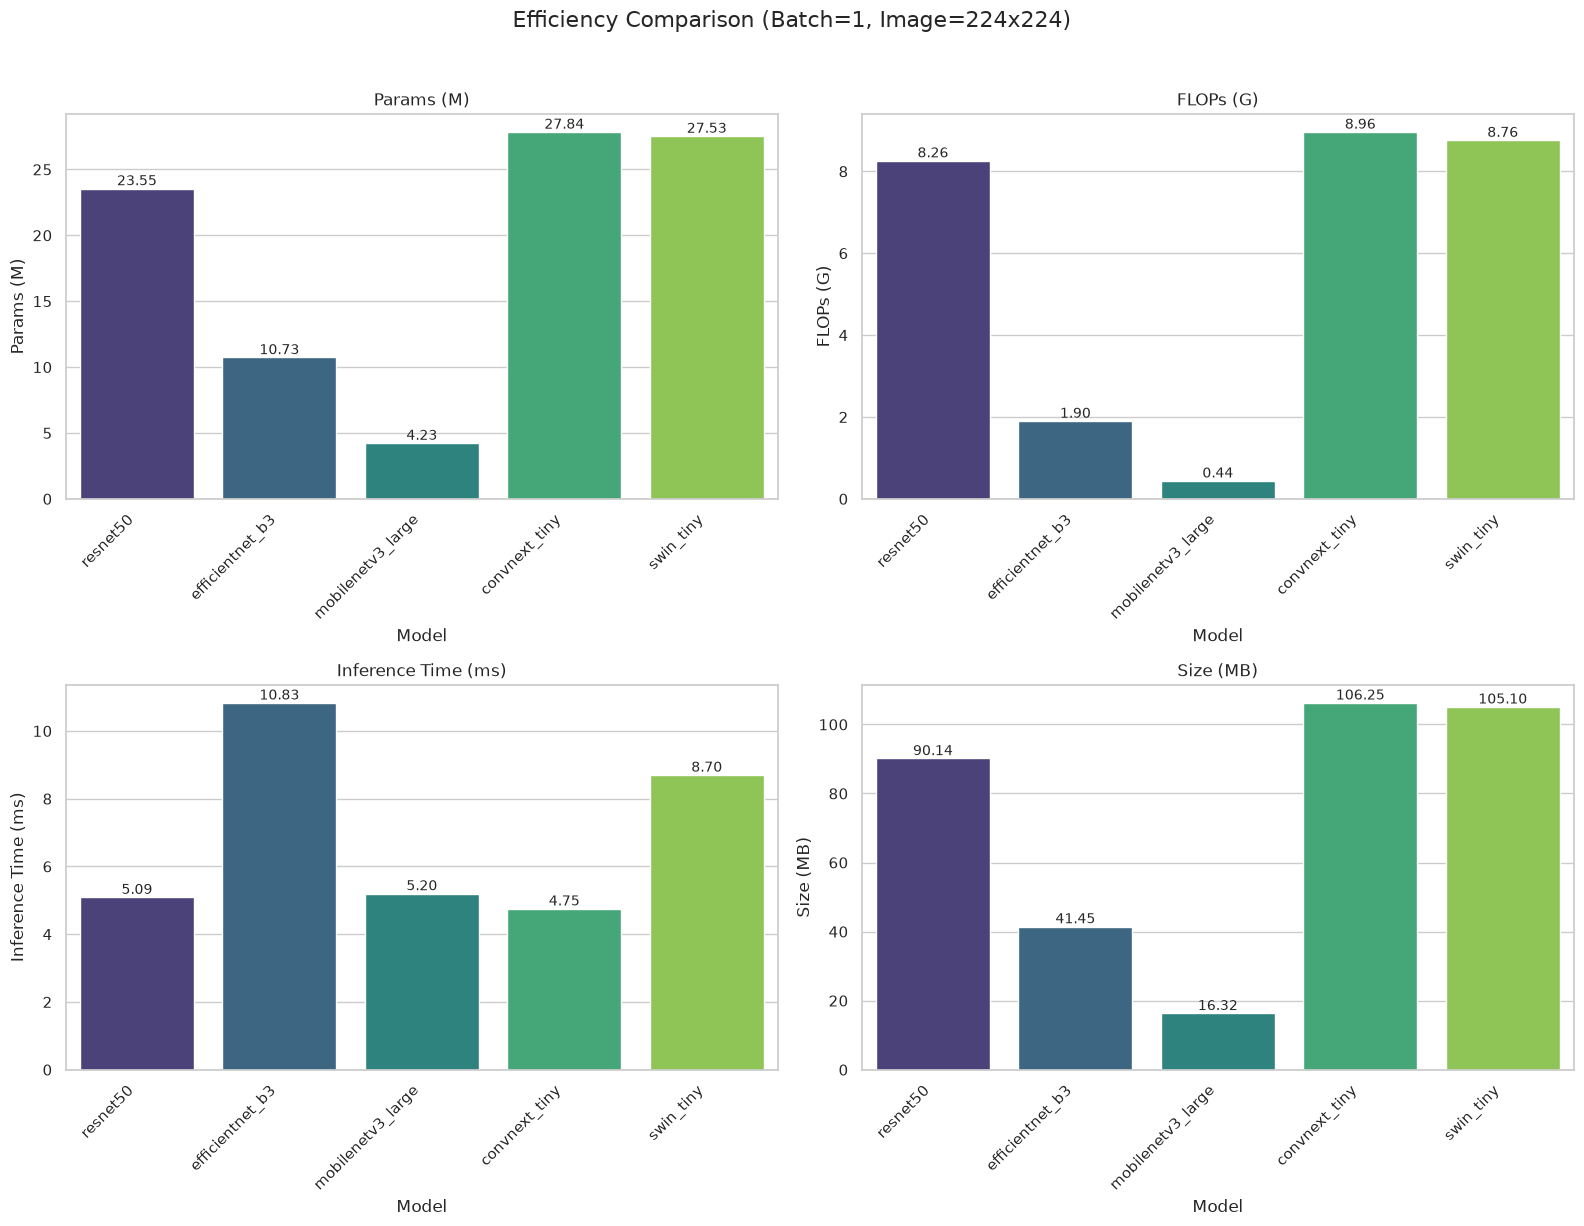

In [8]:
# Visualization
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Efficiency Comparison (Batch=1, Image=224x224)', fontsize=16, y=1.02)

metrics = ["Params (M)", "FLOPs (G)", "Inference Time (ms)", "Size (MB)"]
colors = sns.color_palette("viridis", len(MODELS))

for i, metric in enumerate(metrics):
    ax = axes[i//2, i%2]
    sns.barplot(data=df_results, x="Model", y=metric, ax=ax, palette=colors)
    ax.set_title(metric)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    
    # Add values on top of bars
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.2f}", 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', fontsize=10)

plt.tight_layout()
vis_path = out_dir / "efficiency_comparison.png"
plt.savefig(vis_path, dpi=300, bbox_inches='tight')
print(f"[Saved] Plot to {vis_path}")
plt.show()